# Supplemental Figure 5, Panel D

Comparison of log2FC nascent transcription (PRO-seq) and log2FC steady-state expression (RNA-seq) at genes identified as 1h IFN-gamma induced from RNA_seq, as well as overlap between steady-state induced nascent transcription induced gene sets

*Output: panelD_scatter.pdf, panelD_venn.pdf*

# Setup

In [1]:
library(tidyverse)
library(RColorBrewer)
library(ggrastr)
library(VennDiagram)
library(grid)
library(here)
here::i_am("figures/SuppFig5/PanelD/PanelD_scatter.ipynb")
sessionInfo()


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: grid

Loading required package: futile.logger

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] grid      stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] here_1.0.2          VennDiagram_1.8.2   futile.logger_1.4.3
 [4] ggrastr_1.0.2       RColorBrewer_1.1-3  lubridate_1.9.4    
 [7] forcats_1.0.0       stringr_1.5.1       dplyr_1.1.4        
[10] purrr_1.0.2         readr_2.1.5         tidyr_1.3.1        
[13] tibble_3.2.1   

# Load data

In [3]:
ifn <- read.delim(
    here("inputs","DEGs","GM12878","BAFinh_stimulus","PROseq","PRO_DEGs_IFN_Veh.tsv"), 
    sep='\t')

ifn_steady_state <- read.delim(
    here("inputs","DEGs","GM12878","BAFinh_stimulus","4rep", "IFN_1h_DEGs.tsv"), 
    sep='\t')

steady_state_up <- (ifn_steady_state %>% filter(change=="up"))$gene

# generate plots

**scatter plot**

Warning message in left_join(ifn_steady_state, ifn, by = "gene"):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 3010 of `x` matches multiple rows in `y`.
ℹ Row 2990 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”
Warning message in left_join(ifn_steady_state, ifn, by = "gene"):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 3010 of `x` matches multiple rows in `y`.
ℹ Row 2990 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_smooth()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed

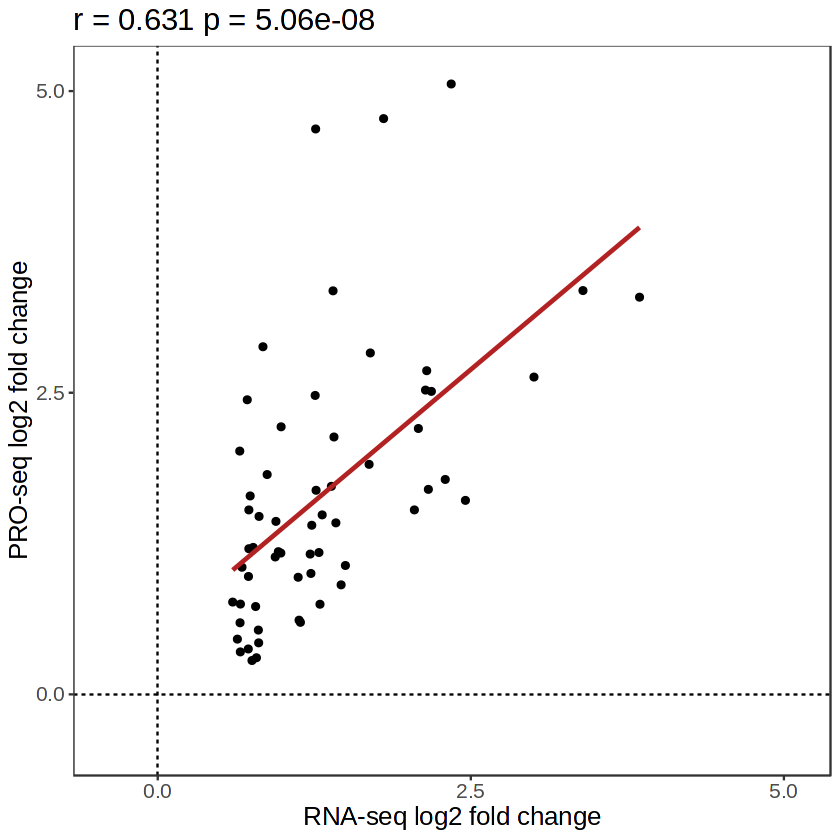

In [75]:
# Pearson correlation test on RNA-seq and PRO-seq log2FCs
stats <- left_join(ifn_steady_state, ifn, by="gene") %>%
    filter(gene %in% steady_state_up) %>%
    summarize(p=cor.test(log2FoldChange.x, log2FoldChange.y)$p.value,
             r=cor.test(log2FoldChange.x, log2FoldChange.y)$estimate)

# make plot
left_join(ifn_steady_state, ifn, by="gene") %>%
    filter(gene %in% steady_state_up) %>%
    ggplot(aes(x=log2FoldChange.x, y=log2FoldChange.y)) +
    theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)) +
    geom_vline(xintercept=0, linetype=2) +
    geom_hline(yintercept=0, linetype=2) +
    geom_point() +
    geom_smooth(method=lm, se=F, color="firebrick") +
    xlab("RNA-seq log2 fold change") + 
    ylab("PRO-seq log2 fold change") +
    ggtitle(paste("r =", format(stats$r, digits=3), "p =", format(stats$p, digits=3))) +
    scale_x_continuous(limits=c(-.4,5.1), breaks=c(0,2.5,5)) +
    scale_y_continuous(limits=c(-.4,5.1), breaks=c(0,2.5,5)) 


ggsave("panelD_scatter.pdf", height=5.5, width=5.5)

**Venn diagram**

In [76]:
# sets are gene names significantly induced in RNA-seq and PRO-seq at 1h IFN-gamma stimulus
sets <- list(RNA=steady_state_up,
            PRO=ifn[ifn$change=="up","gene"])

# Chi-squared test for significance of overlap
p <- (left_join(ifn_steady_state, ifn, by="gene") %>%
    mutate(change.x=change.x=="up", change.y=change.y=="up") %>%
    select(change.x,change.y) %>%
    table() %>%
    chisq.test())$p.value

# Make Venn diagram
venn <- venn.diagram(
  x = sets,
  filename = NULL,
  fill = c("#01665E", "#B35806"),
  alpha = 0.35,
  col = c("#01665E", "#B35806"),
  lwd = 1.5,
  cex = 1.2,
  fontfamily = "sans",
  cat.cex = 1.1,
  cat.fontfamily = "sans",
  cat.col = "black",
  cat.pos = c(-20, 20),
  cat.dist = c(0.05, 0.05),
  margin = 0.12,
  main=paste("p=", format(p, digits=3))
)

pdf("panelD_venn.pdf", width = 4, height = 4, useDingbats = FALSE)
grid.draw(venn)
dev.off()

Warning message in left_join(ifn_steady_state, ifn, by = "gene"):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 3010 of `x` matches multiple rows in `y`.
ℹ Row 2990 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”
Warning message in chisq.test(.):
“Chi-squared approximation may be incorrect”


pdf 
  2